In [1]:
import gymnasium as gym
from Deep_Q_learning import *
import matplotlib.pyplot as plt
from IPython.display import display, clear_output


## Get familiar with the environment and see what is a random policy.

KeyboardInterrupt: 

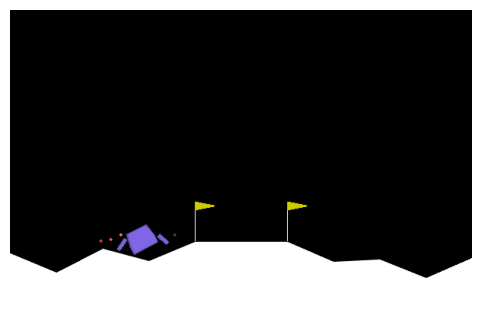

In [2]:
env = gym.make('LunarLander-v3',render_mode='rgb_array')


for episode in range(5):
    current_observation, info = env.reset()

    episode_over = False
    total_reward = 0

    success=0
    while not episode_over:
        action=env.action_space.sample()
        new_observation, reward, terminated, truncated, info = env.step(action)

        current_observation=new_observation
        episode_over = terminated or truncated


        #### Visualization ####
        frame = env.render()
        clear_output(wait=True)
        plt.figure(figsize=(6, 4))
        plt.imshow(frame)
        plt.axis('off')
        display(plt.gcf())
        plt.close()
        #### Visualization ####

env.close()


## Train an agent with deep Q-learning

### Definition of the hyperparameters and creation of an agent (and a new environment)

In [6]:
n_episodes=10
start_eps=1.0
batch_size=64
update_weights_period=1000


display_train=1
Display_dynamic_graph=True

In [7]:
env = gym.make('LunarLander-v3')
env = gym.wrappers.RecordEpisodeStatistics(env, buffer_length=n_episodes)

agent=Agent(
    env=env,

    start_learning_rate=0.005,
    start_factor_lr=1.0,
    end_factor_lr=0.02,
    total_iters_lr=int(n_episodes/2),
    
    start_epsilon=start_eps,
    epsilon_decay = start_eps / (n_episodes/2),
    final_epsilon=0.1,
    gamma=0.99
    )

buffer = ReplayBuffer(capacity=100_000)

(Visualization purpose)

In [8]:
def get_moving_avgs(arr, window, convolution_mode):
    """Compute moving average to smooth noisy data."""
    return np.convolve(
        np.array(arr).flatten(),
        np.ones(window),
        mode=convolution_mode
    ) / window

### Training loop

/var/folders/4f/q819rgs51dx9dzsqx42ynnb40000gn/T/ipykernel_21773/2448522956.py:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


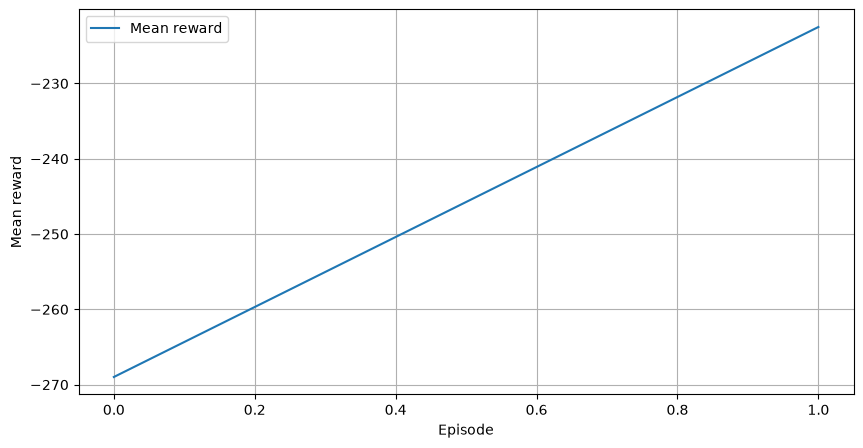

Model saved: models/model_luner_lander.pth

Training done


In [9]:
if (Display_dynamic_graph):
    plt.ion() 
    fig, ax = plt.subplots(figsize=(10, 5))
    line, = ax.plot([], [], label="Mean reward")
    ax.set_xlabel("Episode")
    ax.set_ylabel("Mean reward")
    # ax.set_title("DQN - LunarLander training")
    ax.legend()
    ax.grid()
    fig.show()


count_update=0
Training_loss=[]

for episode in range(n_episodes):
    current_observation, info = env.reset()
    episode_over = False

    while not episode_over:
        action=agent.eps_greedy_action(state=current_observation)
        new_observation, reward, terminated, truncated, info = env.step(action)
        buffer.add(current_observation, action, reward, new_observation, int(terminated))

        current_observation=new_observation
        episode_over = terminated or truncated


        if (len(buffer)>batch_size):
            count_update+=1

            # Liste_states,Liste_actions,Liste_rewards,Liste_next_states,Liste_terminated=buffer.sample(batch_size)
            # agent.update(
            #             Liste_states=Liste_states,
            #             Liste_actions=Liste_actions,
            #             Liste_rewards=Liste_rewards,
            #             Liste_next_states=Liste_next_states,
            #             Liste_terminated=Liste_terminated
            #             )

            # Update method is One batch of Gradient Descent 
            loss=agent.update(*buffer.sample(batch_size))


        if (count_update>update_weights_period):
            count_update=0

            # Load the new weights on the target network each update_weights_period
            agent.network_copy.load_state_dict(agent.main_network.state_dict())

    agent.update_epsilon()
    agent.scheduler.step()
    Training_loss.append(loss)
    if (episode != 0 and episode%display_train==0):
        current_lr = agent.optimizer.param_groups[0]['lr']

        # print(f"\nEpisode {episode} | LR = {current_lr:.6f}")
        # print(f"Episode mean length: {np.array(env.length_queue)[-display_train:].mean()}")

        if (Display_dynamic_graph):
            y=get_moving_avgs(env.return_queue,display_train,"valid")
            x = np.arange(len(y))

            line.set_data(x, y)
            ax.relim()
            ax.autoscale_view()
            fig.canvas.draw_idle()
            fig.canvas.flush_events()
            plt.pause(0.01)


agent.save_network("model_luner_lander")

plt.ioff()
plt.show()
print("\nTraining done")

### Visualization of the training (copyright from Gymnasium)

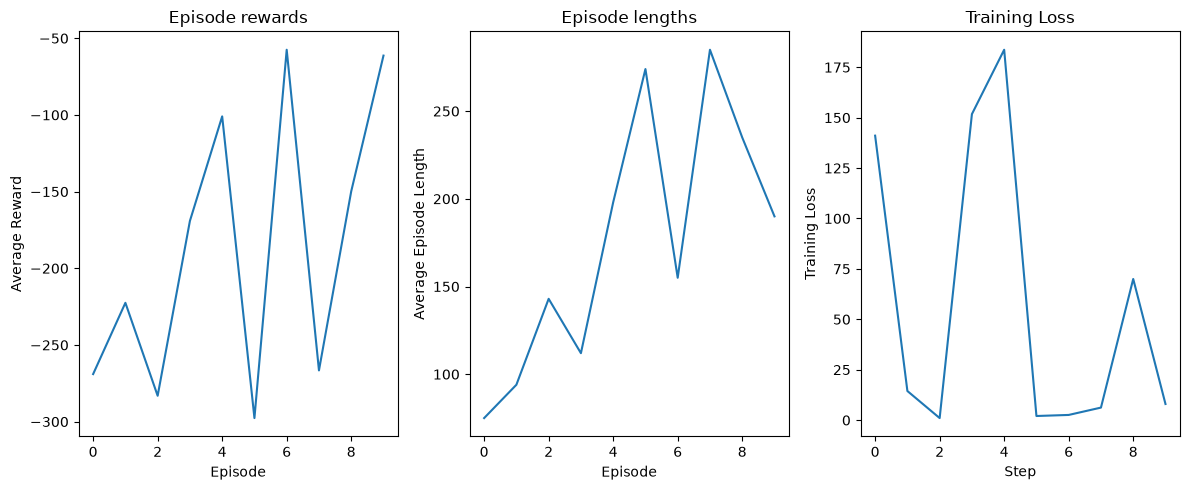

In [10]:


# Smooth over a 500-episode window
rolling_length = display_train
fig, axs = plt.subplots(ncols=3, figsize=(12, 5))

# Episode rewards (win/loss performance)
axs[0].set_title("Episode rewards")
reward_moving_average = get_moving_avgs(
    env.return_queue,
    rolling_length,
    "valid"
)
axs[0].plot(range(len(reward_moving_average)), reward_moving_average)
axs[0].set_ylabel("Average Reward")
axs[0].set_xlabel("Episode")

# Episode lengths (how many actions per hand)
axs[1].set_title("Episode lengths")
length_moving_average = get_moving_avgs(
    env.length_queue,
    rolling_length,
    "valid"
)
axs[1].plot(range(len(length_moving_average)), length_moving_average)
axs[1].set_ylabel("Average Episode Length")
axs[1].set_xlabel("Episode")

# Training error (how much we're still learning)
axs[2].set_title("Training Loss")
training_loss_moving_average = get_moving_avgs(
    Training_loss,
    rolling_length,
    "same"
)
axs[2].plot(range(len(training_loss_moving_average)), training_loss_moving_average)
axs[2].set_ylabel("Training Loss")
axs[2].set_xlabel("Step")

plt.tight_layout()
plt.show()